In [2]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/PS_20174392719_1491204439457_log.csv")

df_sample = pd.read_csv(data_path, nrows=1000)

print("Sample shape:", df_sample.shape)
display(df_sample.head())

Sample shape: (1000, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
print(df_sample.columns.tolist())

['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [4]:
df_sample.head(5).to_string()

'   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig     nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud\n0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36  M1979787155             0.0             0.0        0               0\n1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72  M2044282225             0.0             0.0        0               0\n2     1  TRANSFER    181.00  C1305486145          181.0            0.00   C553264065             0.0             0.0        1               0\n3     1  CASH_OUT    181.00   C840083671          181.0            0.00    C38997010         21182.0             0.0        1               0\n4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86  M1230701703             0.0             0.0        0               0'

In [5]:
df_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            1000 non-null   int64  
 1   type            1000 non-null   str    
 2   amount          1000 non-null   float64
 3   nameOrig        1000 non-null   str    
 4   oldbalanceOrg   1000 non-null   float64
 5   newbalanceOrig  1000 non-null   float64
 6   nameDest        1000 non-null   str    
 7   oldbalanceDest  1000 non-null   float64
 8   newbalanceDest  1000 non-null   float64
 9   isFraud         1000 non-null   int64  
 10  isFlaggedFraud  1000 non-null   int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 86.1 KB


In [6]:
df_sample.isna().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [7]:
df_sample["isFraud"].value_counts()

isFraud
0    991
1      9
Name: count, dtype: int64

In [8]:
df_sample["isFraud"].value_counts(normalize=True) * 100

isFraud
0    99.1
1     0.9
Name: proportion, dtype: float64

In [9]:
df_sample["type"].value_counts()

type
PAYMENT     437
CASH_OUT    230
CASH_IN     183
TRANSFER     99
DEBIT        51
Name: count, dtype: int64

In [10]:
df_sample["type"].value_counts(normalize=True).mul(100).round(2)

type
PAYMENT     43.7
CASH_OUT    23.0
CASH_IN     18.3
TRANSFER     9.9
DEBIT        5.1
Name: proportion, dtype: float64

In [11]:
df_sample.groupby("type")["isFraud"].agg(
    transactions="count",
    fraud_cases="sum",
    fraud_rate="mean"
)

,transactions,fraud_cases,fraud_rate
type,,,
CASH_IN,183,0,0.000000
CASH_OUT,230,5,0.021739
DEBIT,51,0,0.000000
PAYMENT,437,0,0.000000
TRANSFER,99,4,0.040404


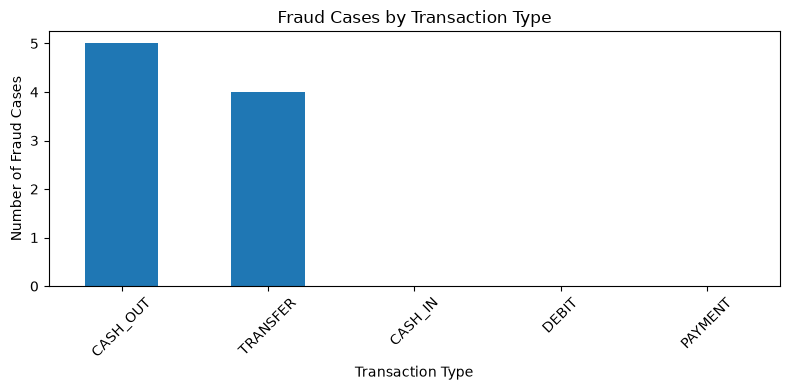

In [12]:
import matplotlib.pyplot as plt

fraud_counts = (
    df_sample.groupby("type")["isFraud"]
    .sum()
    .sort_values(ascending=False)
)

fraud_counts.plot(kind="bar", figsize=(8, 4))

plt.title("Fraud Cases by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Fraud Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
df_sample.groupby("isFraud")["amount"].agg(
    transaction_count="count",
    mean_amount="mean",
    median_amount="median",
    max_amount="max"
).round(2)

,transaction_count,mean_amount,median_amount,max_amount
isFraud,,,,
0,991,116228.93,14420.66,2545478.01
1,9,335184.10,20128.00,1277212.77


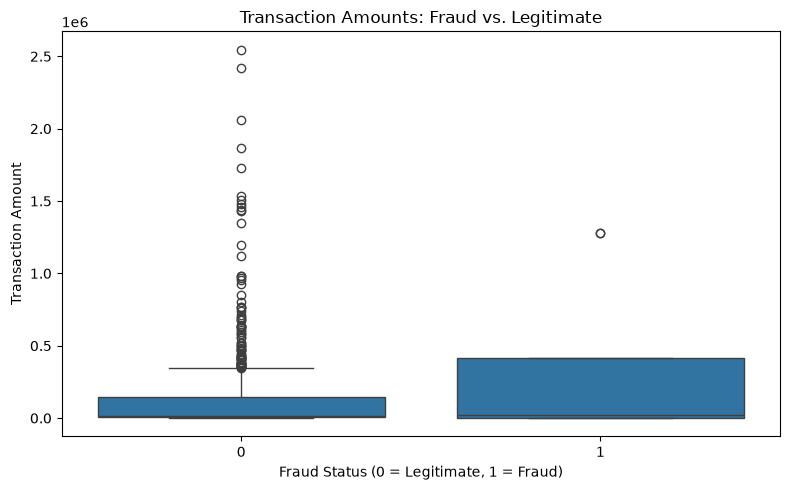

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_sample,
    x="isFraud",
    y="amount"
)

plt.title("Transaction Amounts: Fraud vs. Legitimate")
plt.xlabel("Fraud Status (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

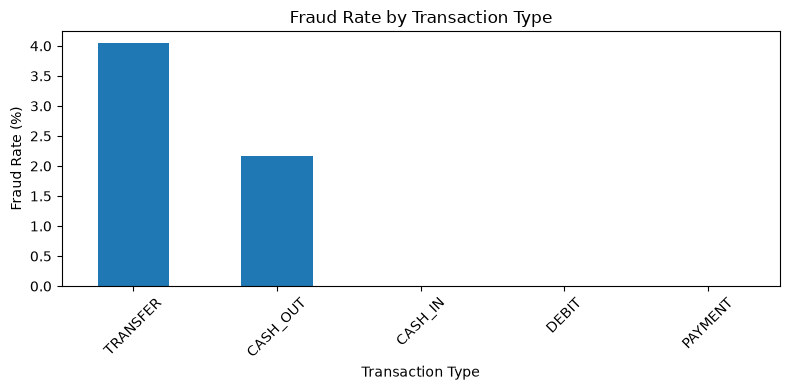

In [15]:
fraud_rates = (
    df_sample.groupby("type")["isFraud"]
    .mean()
    .sort_values(ascending=False) * 100
)

fraud_rates.plot(kind="bar", figsize=(8, 4))

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
print("Duplicate rows:", df_sample.duplicated().sum())

print("Zero-amount transactions:", (df_sample["amount"] == 0).sum())

print("Negative-amount transactions:", (df_sample["amount"] < 0).sum())

Duplicate rows: 0
Zero-amount transactions: 0
Negative-amount transactions: 0


## Initial Exploratory Data Analysis Findings

- The initial sample contains 1,000 transactions and 11 columns.
- The sample contains 9 fraudulent transactions and 991 legitimate transactions, so the fraud class is highly underrepresented.
- `TRANSFER` has the highest observed fraud rate (4.04%), followed by `CASH_OUT` (2.17%).
- Fraudulent transactions have a higher median amount than legitimate transactions in this sample, but legitimate transactions include larger maximum amounts.
- No duplicate rows, zero-amount transactions, or negative-amount transactions were found in the sample.
- These findings are preliminary because the sample contains only the first 1,000 rows and just 9 fraud cases. Further analysis on the full dataset is required before drawing firm conclusions.

### Modeling consideration

Fraud detection should not rely on transaction amount or transaction type alone. Model evaluation should account for class imbalance, and candidate features must be checked for potential data leakage.

In [2]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/PS_20174392719_1491204439457_log.csv")

print("File exists:", data_path.exists())

File exists: True


In [3]:
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

print("\nFraud counts:")
print(df["isFraud"].value_counts())

print("\nFraud percentages:")
print((df["isFraud"].value_counts(normalize=True) * 100).round(4))

Dataset shape: (6362620, 11)

Fraud counts:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud percentages:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64


## Full Dataset Overview

- Total transactions: 6,362,620
- Total columns: 11
- Legitimate transactions: 6,354,407 (99.8709%)
- Fraudulent transactions: 8,213 (0.1291%)

### Key finding: Severe class imbalance

Fraudulent transactions represent only 0.1291% of the dataset, approximately 1 in every 775 transactions. A model predicting every transaction as legitimate could achieve approximately 99.87% accuracy while detecting no fraud.

Therefore, accuracy alone is not an appropriate evaluation metric. Future models should be assessed using precision, recall, F1-score, and precision-recall AUC, alongside business costs.

### Sampling limitation

The initial 1,000-row sample had a fraud rate of 0.9%, substantially higher than the full dataset's 0.1291%. This demonstrates why the first rows of a dataset should not be assumed to represent its overall distribution.

In [4]:
fraud_by_type = (
    df.groupby("type")["isFraud"]
    .agg(
        total_transactions="count",
        fraud_cases="sum",
        fraud_rate="mean"
    )
)

fraud_by_type["fraud_rate_pct"] = fraud_by_type["fraud_rate"] * 100

fraud_by_type = fraud_by_type.sort_values(
    "fraud_rate_pct",
    ascending=False
)

display(fraud_by_type.round(4))

,total_transactions,fraud_cases,fraud_rate,fraud_rate_pct
type,,,,
TRANSFER,532909,4097,0.0077,0.7688
CASH_OUT,2237500,4116,0.0018,0.1840
CASH_IN,1399284,0,0.0000,0.0000
DEBIT,41432,0,0.0000,0.0000
PAYMENT,2151495,0,0.0000,0.0000


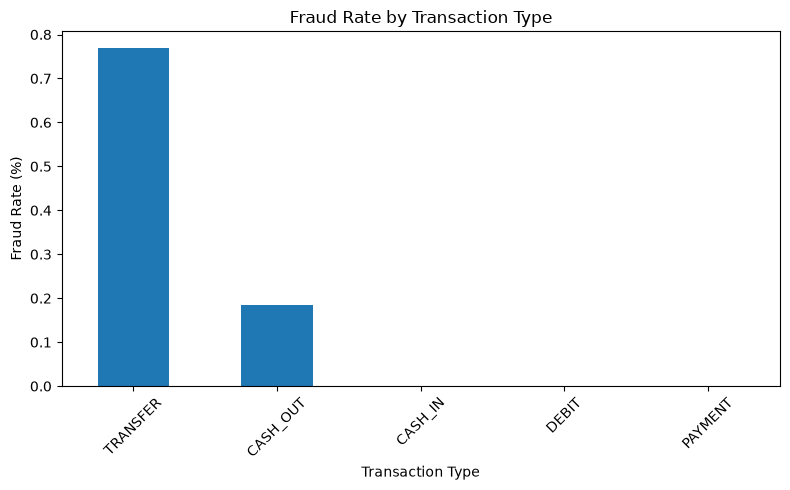

In [5]:
import matplotlib.pyplot as plt

fraud_by_type["fraud_rate_pct"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
amount_analysis = (
    df.groupby("isFraud")["amount"]
    .agg(
        transaction_count="count",
        total_amount="sum",
        mean_amount="mean",
        median_amount="median",
        max_amount="max"
    )
)

display(amount_analysis.round(2))

,transaction_count,total_amount,mean_amount,median_amount,max_amount
isFraud,,,,,
0,6354407,1.132337e+12,178197.04,74684.72,92445516.64
1,8213,1.205642e+10,1467967.30,441423.44,10000000.00


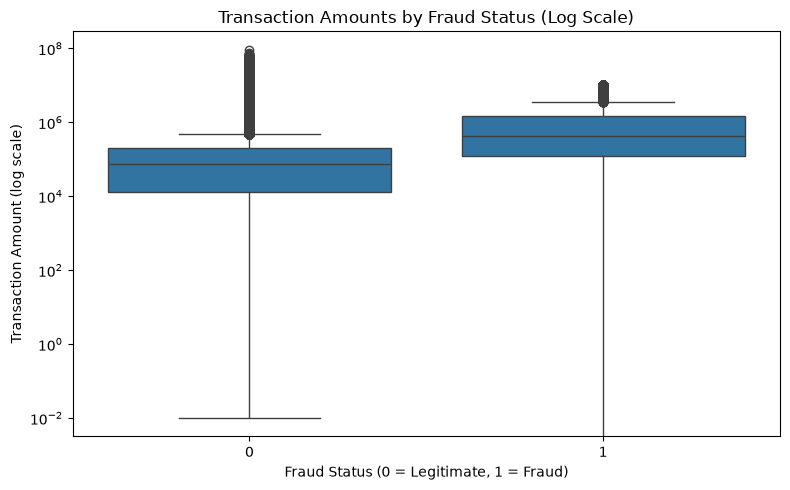

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="isFraud",
    y="amount"
)

plt.yscale("log")
plt.title("Transaction Amounts by Fraud Status (Log Scale)")
plt.xlabel("Fraud Status (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount (log scale)")
plt.tight_layout()
plt.show()

In [8]:
fraud_amount_by_type = (
    df[df["isFraud"] == 1]
    .groupby("type")["amount"]
    .agg(
        fraud_cases="count",
        total_fraud_amount="sum",
        average_fraud_amount="mean"
    )
    .sort_values("total_fraud_amount", ascending=False)
)

display(fraud_amount_by_type.round(2))

,fraud_cases,total_fraud_amount,average_fraud_amount
type,,,
TRANSFER,4097,6.067213e+09,1480891.67
CASH_OUT,4116,5.989202e+09,1455102.59


## Fraud Amount Analysis by Transaction Type

- TRANSFER: 4,097 fraud cases, with a combined transaction value of approximately 6.067 billion.
- CASH_OUT: 4,116 fraud cases, with a combined transaction value of approximately 5.989 billion.
- TRANSFER has the higher total value of fraud-labeled transactions and a slightly higher average transaction amount.
- CASH_OUT has 19 more fraud cases than TRANSFER.
- All 8,213 fraud-labeled transactions in this dataset belong to TRANSFER or CASH_OUT.

### Business interpretation

TRANSFER and CASH_OUT warrant particular attention in further fraud analysis. Prioritization should consider fraud rate, case volume, transaction value, and the cost of false positives.

The total transaction value labeled as fraudulent should not be interpreted as confirmed financial loss.

### Modeling consideration

These results describe the dataset and do not establish causation. Additional analysis is needed before selecting model features or making operational recommendations.

In [9]:
df["origin_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

df["origin_balance_error"] = (
    df["origin_balance_change"] - df["amount"]
)

print("Balance change summary:")
display(df["origin_balance_change"].describe().round(2))

print("\nBalance error summary:")
display(df["origin_balance_error"].describe().round(2))

Balance change summary:


count     6362620.00
mean       -21230.56
std        146643.29
min      -1915267.90
25%             0.00
50%             0.00
75%         10150.44
max      10000000.00
Name: origin_balance_change, dtype: float64


Balance error summary:


count     6362620.00
mean      -201092.47
std        606650.46
min     -92445516.64
25%       -249641.09
50%        -68677.26
75%         -2954.23
max             0.01
Name: origin_balance_error, dtype: float64

In [10]:
balance_error_by_fraud = (
    df.groupby("isFraud")["origin_balance_error"]
    .agg(
        transaction_count="count",
        mean_error="mean",
        median_error="median",
        zero_error_count=lambda x: (x.abs() < 0.01).sum()
    )
)

display(balance_error_by_fraud.round(2))

,transaction_count,mean_error,median_error,zero_error_count
isFraud,,,,
0,6354407,-201338.56,-69049.31,1288026
1,8213,-10692.33,0.00,8168


In [11]:
balance_error_by_type = (
    df.groupby("type")["origin_balance_error"]
    .agg(
        transaction_count="count",
        mean_error="mean",
        median_error="median",
        zero_error_rate=lambda x: (x.abs() < 0.01).mean() * 100
    )
    .sort_values("zero_error_rate", ascending=False)
)

display(balance_error_by_type.round(2))

,transaction_count,mean_error,median_error,zero_error_rate
type,,,,
DEBIT,41432,-1997.98,-0.00,70.21
PAYMENT,2151495,-6678.67,-380.78,46.28
CASH_OUT,2237500,-147724.35,-119512.32,11.05
TRANSFER,532909,-866493.31,-448795.46,4.53
CASH_IN,1399284,-337835.45,-286848.82,0.00


In [12]:
balance_error_by_type_and_fraud = (
    df.groupby(["type", "isFraud"])["origin_balance_error"]
    .agg(
        transaction_count="count",
        median_error="median",
        zero_error_rate=lambda x: (x.abs() < 0.01).mean() * 100
    )
)

display(balance_error_by_type_and_fraud.round(2))

transaction_count  median_error  zero_error_rate
type     isFraud                                                  
CASH_IN  0                  1399284    -286848.82             0.00
CASH_OUT 0                  2233384    -119824.22            10.88
         1                     4116          0.00            99.42
DEBIT    0                    41432         -0.00            70.21
PAYMENT  0                  2151495       -380.78            46.28
TRANSFER 0                   528812    -454033.08             3.80
         1                     4097          0.00            99.49

## Balance Error Analysis by Transaction Type and Fraud Status

- Fraud-labeled CASH_OUT transactions have an approximately zero balance-error rate of 99.42%, compared with 10.88% for legitimate CASH_OUT transactions.
- Fraud-labeled TRANSFER transactions have an approximately zero balance-error rate of 99.49%, compared with 3.80% for legitimate TRANSFER transactions.
- The median balance error for fraud-labeled transactions is zero for both transaction types, while legitimate transactions have substantially negative median errors.

### Interpretation

The balance-error feature strongly distinguishes fraud-labeled transactions from legitimate transactions within CASH_OUT and TRANSFER in this dataset.

However, this association does not establish causation or guarantee performance on new data. The pattern may partly reflect the simulator's transaction-generation and fraud-labeling rules.

### Modeling caution: prediction timing and leakage

The feature uses the sender's post-transaction balance (`newbalanceOrig`). It should not automatically be included in a model intended to predict fraud before transaction completion. Feature selection must account for what information is available at the intended prediction time.

In [13]:
fraud_counts_by_type = pd.crosstab(
    df["type"],
    df["isFraud"]
)

fraud_counts_by_type.columns = [
    "legitimate",
    "fraud"
]

fraud_counts_by_type["total"] = (
    fraud_counts_by_type["legitimate"]
    + fraud_counts_by_type["fraud"]
)

fraud_counts_by_type["fraud_rate_pct"] = (
    fraud_counts_by_type["fraud"]
    / fraud_counts_by_type["total"]
    * 100
)

display(fraud_counts_by_type.round(4))

,legitimate,fraud,total,fraud_rate_pct
type,,,,
CASH_IN,1399284,0,1399284,0.0000
CASH_OUT,2233384,4116,2237500,0.1840
DEBIT,41432,0,41432,0.0000
PAYMENT,2151495,0,2151495,0.0000
TRANSFER,528812,4097,532909,0.7688


In [14]:
feature_review = pd.DataFrame({
    "column": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "unique_values": [
        df[col].nunique()
        for col in df.columns
    ]
})

display(feature_review)

,column,data_type,unique_values
0,step,int64,743
1,type,str,5
2,amount,float64,5316900
3,nameOrig,str,6353307
4,oldbalanceOrg,float64,1845844
5,newbalanceOrig,float64,2682586
6,nameDest,str,2722362
7,oldbalanceDest,float64,3614697
8,newbalanceDest,float64,3555499
9,isFraud,int64,2


In [15]:
target = "isFraud"

features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

X = df[features].copy()
y = df[target].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())
print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (6362620, 5)
Target shape: (6362620,)

Feature columns:
['step', 'type', 'amount', 'oldbalanceOrg', 'oldbalanceDest']

Target distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [17]:
import numpy as np

In [18]:
numeric_features = X.select_dtypes(include="number")

print("Infinite values per numeric feature:")
display(
    pd.Series(
        {
            col: int((~np.isfinite(numeric_features[col])).sum())
            for col in numeric_features.columns
        },
        name="infinite_count"
    )
)

Infinite values per numeric feature:


step              0
amount            0
oldbalanceOrg     0
oldbalanceDest    0
Name: infinite_count, dtype: int64

In [19]:
print("Existing flag counts:")
display(df["isFlaggedFraud"].value_counts())

print("\nExisting flag vs. actual fraud:")
display(pd.crosstab(
    df["isFlaggedFraud"],
    df["isFraud"],
    rownames=["isFlaggedFraud"],
    colnames=["isFraud"]
))

print("\nFraud detection rate of the existing flag:")
fraud_total = df["isFraud"].sum()
flagged_fraud = (
    (df["isFlaggedFraud"] == 1) & (df["isFraud"] == 1)
).sum()

print(f"Fraud cases flagged: {flagged_fraud:,} / {fraud_total:,}")
print(f"Recall: {flagged_fraud / fraud_total:.2%}")

Existing flag counts:


isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64


Existing flag vs. actual fraud:


isFraud,0,1
isFlaggedFraud,,
0,6354407,8197
1,0,16



Fraud detection rate of the existing flag:
Fraud cases flagged: 16 / 8,213
Recall: 0.19%


### Existing Fraud Flag Analysis

The dataset's existing `isFlaggedFraud` indicator flags only 16 of 6,362,620 transactions. All 16 flagged transactions are labeled as fraud, but the indicator identifies only 16 of the 8,213 fraud cases, achieving a recall of approximately 0.19%.

This means the existing flag misses 8,197 fraud cases (approximately 99.81%). Although its observed precision is 100% in this dataset, that result is based on only 16 flagged transactions and should be interpreted cautiously.

**Modeling decision:** Exclude `isFlaggedFraud` from the initial predictive model. Treat it as a baseline for comparison rather than an input feature, so the model can learn from transaction attributes independently of this existing detection rule.

In [20]:

# Summarize transaction volume and fraud by simulation step
step_summary = df.groupby("step").agg(
    transactions=("isFraud", "size"),
    fraud_cases=("isFraud", "sum")
)

step_summary["fraud_rate_pct"] = (
    step_summary["fraud_cases"] / step_summary["transactions"] * 100
)

display(step_summary.describe().round(3))


,transactions,fraud_cases,fraud_rate_pct
count,743.000,743.000,743.000
mean,8563.419,11.054,43.925
std,13388.693,4.999,48.956
min,2.000,0.000,0.000
25%,12.000,8.000,0.075
50%,529.000,10.000,1.916
75%,12317.000,14.000,100.000
max,51352.000,40.000,100.000


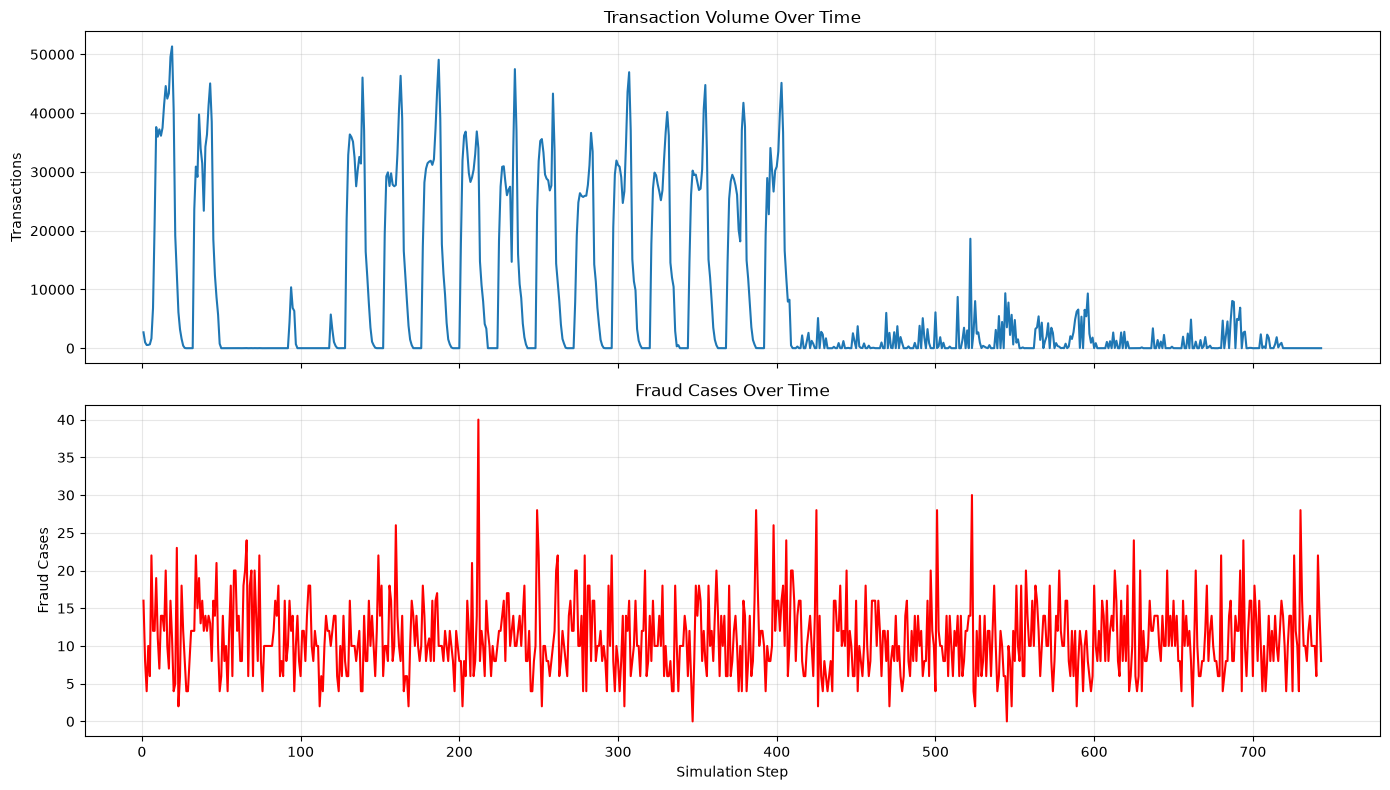

In [21]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(step_summary.index, step_summary["transactions"])
axes[0].set_title("Transaction Volume Over Time")
axes[0].set_ylabel("Transactions")
axes[0].grid(alpha=0.3)

axes[1].plot(
    step_summary.index,
    step_summary["fraud_cases"],
    color="red"
)
axes[1].set_title("Fraud Cases Over Time")
axes[1].set_xlabel("Simulation Step")
axes[1].set_ylabel("Fraud Cases")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [22]:
mid_step = df["step"].median()

df["time_period"] = np.where(
    df["step"] <= mid_step,
    "First half",
    "Second half"
)

period_summary = df.groupby("time_period", observed=True).agg(
    transactions=("isFraud", "size"),
    fraud_cases=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean")
)

period_summary["fraud_rate_pct"] = period_summary["fraud_rate"] * 100

display(period_summary.drop(columns="fraud_rate").round(4))

,transactions,fraud_cases,fraud_rate_pct
time_period,,,
First half,3186492,2705,0.0849
Second half,3176128,5508,0.1734


### Temporal Fraud Analysis

Fraud prevalence increases over the simulation timeline. In the first half, 2,705 of 3,186,492 transactions are labeled fraudulent, giving a fraud rate of 0.0849%. In the second half, 5,508 of 3,176,128 transactions are fraudulent, giving a rate of 0.1734%.

The second-half fraud rate is approximately 2.04 times the first-half rate, despite similar transaction volumes. This indicates that fraud prevalence is not constant over time and may affect model generalization.

**Modeling implication:** Evaluate a chronological train/test split, training on earlier transactions and testing on later ones. This provides a more realistic assessment of performance on future transactions than a random split alone. The observed change in fraud prevalence does not, by itself, establish its cause.

In [23]:
# Inspect the time range
print("Minimum step:", df["step"].min())
print("Maximum step:", df["step"].max())
print("Number of unique steps:", df["step"].nunique())

# Find the step boundary closest to an 80/20 chronological split
step_volume = df.groupby("step").size().sort_index()
cumulative_share = step_volume.cumsum() / step_volume.sum()

split_step = cumulative_share.index[
    (cumulative_share - 0.8).abs().argmin()
]

print("\nProposed split step:", split_step)
print(f"Share of transactions through split step: {cumulative_share.loc[split_step]:.2%}")
print(f"Share of transactions after split step: {1 - cumulative_share.loc[split_step]:.2%}")

Minimum step: 1
Maximum step: 743
Number of unique steps: 743

Proposed split step: 354
Share of transactions through split step: 79.67%
Share of transactions after split step: 20.33%


In [24]:
split_step = 354

train_mask = df["step"] <= split_step
test_mask = df["step"] > split_step

X_train = X.loc[train_mask, features].copy()
X_test = X.loc[test_mask, features].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training transactions:", len(X_train))
print("Testing transactions:", len(X_test))

print("\nTraining period:", df.loc[train_mask, "step"].min(),
      "to", df.loc[train_mask, "step"].max())
print("Testing period:", df.loc[test_mask, "step"].min(),
      "to", df.loc[test_mask, "step"].max())

print("\nFraud cases in training:", int(y_train.sum()))
print("Fraud cases in testing:", int(y_test.sum()))

print("\nTraining fraud rate:", f"{y_train.mean() * 100:.4f}%")
print("Testing fraud rate:", f"{y_test.mean() * 100:.4f}%")

Training transactions: 5069097
Testing transactions: 1293523

Training period: 1 to 354
Testing period: 355 to 743

Fraud cases in training: 3955
Fraud cases in testing: 4258

Training fraud rate: 0.0780%
Testing fraud rate: 0.3292%


In [25]:
print("Training transaction types:")
display(X_train["type"].value_counts())

print("\nTesting transaction types:")
display(X_test["type"].value_counts())

print("\nCategories present in training:")
print(sorted(X_train["type"].unique()))

print("\nCategories present in testing:")
print(sorted(X_test["type"].unique()))

Training transaction types:


type
CASH_OUT    1796898
PAYMENT     1706555
CASH_IN     1112415
TRANSFER     421007
DEBIT         32222
Name: count, dtype: int64


Testing transaction types:


type
PAYMENT     444940
CASH_OUT    440602
CASH_IN     286869
TRANSFER    111902
DEBIT         9210
Name: count, dtype: int64


Categories present in training:
['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']

Categories present in testing:
['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']


In [28]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_features = ["type"]
numeric_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numeric", "passthrough", numeric_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print(
    "Encoded categories:",
    preprocessor.named_transformers_["categorical"].categories_
)


Processed training shape: (5069097, 9)
Processed testing shape: (1293523, 9)
Encoded categories: [array(['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER'],
      dtype=object)]


In [29]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

model = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Confusion matrix:
[[1256419   32846]
 [    482    3776]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99   1289265
           1       0.10      0.89      0.18      4258

    accuracy                           0.97   1293523
   macro avg       0.55      0.93      0.59   1293523
weighted avg       1.00      0.97      0.98   1293523



In [30]:

from sklearn.metrics import average_precision_score, roc_auc_score

y_scores = model.predict_proba(X_test_processed)[:, 1]

print("Average precision (PR-AUC summary):",
      round(average_precision_score(y_test, y_scores), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_scores), 4))


Average precision (PR-AUC summary): 0.6563
ROC-AUC: 0.9389


In [31]:

from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    y_threshold_pred = (y_scores >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "f1": f1_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "flagged_transactions": int(y_threshold_pred.sum())
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))


,threshold,precision,recall,f1,flagged_transactions
0,0.1,0.1031,0.8868,0.1847,36622
1,0.2,0.1031,0.8868,0.1847,36622
2,0.3,0.1031,0.8868,0.1847,36622
3,0.4,0.1031,0.8868,0.1847,36622
4,0.5,0.1031,0.8868,0.1847,36622
5,0.6,0.1036,0.8854,0.1855,36380
6,0.7,0.1036,0.8854,0.1855,36380
7,0.8,0.1376,0.8520,0.2370,26363
8,0.9,0.2853,0.7520,0.4137,11222


In [32]:

from sklearn.metrics import confusion_matrix

comparison = []

for threshold in [0.5, 0.8, 0.9]:
    predictions = (y_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    comparison.append({
        "threshold": threshold,
        "fraud_caught": tp,
        "fraud_missed": fn,
        "false_alarms": fp,
        "total_flagged": tp + fp
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)


,threshold,fraud_caught,fraud_missed,false_alarms,total_flagged
0,0.5,3776,482,32846,36622
1,0.8,3628,630,22735,26363
2,0.9,3202,1056,8020,11222


### Baseline Model Evaluation and Threshold Analysis

A decision tree classifier (`max_depth=10`, `class_weight="balanced"`) was evaluated on a chronological holdout set containing 1,293,523 transactions from simulation steps 355–743.

At the default threshold of 0.5, the model detected 3,776 of 4,258 fraud cases (88.68% recall), while producing 32,846 false positives. Fraud precision was approximately 10.31%. The model achieved an average precision score of 0.6563 and a ROC-AUC of 0.9389.

Threshold analysis showed that increasing the threshold to 0.9 reduced the number of flagged transactions from 36,622 to 11,222 and reduced false positives from 32,846 to 8,020. However, missed fraud cases increased from 482 to 1,056.

**Business implication:** threshold selection should reflect the relative costs of missed fraud, false alarms, and customer friction. No threshold should be considered optimal without an explicit business objective. Results should also be interpreted in light of the higher fraud prevalence in the later test period and the synthetic nature of the dataset.

In [33]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, average_precision_score, roc_auc_score

# Scale numeric features; one-hot encode transaction type
lr_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), ["type"]),
        ("numeric", StandardScaler(), ["step", "amount", "oldbalanceOrg", "oldbalanceDest"])
    ]
)

lr_model = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train and evaluate on the same chronological split
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)
lr_scores = lr_model.predict_proba(X_test)[:, 1]

print("Classification report:")
print(classification_report(y_test, lr_pred, zero_division=0))

print("Average precision:", round(average_precision_score(y_test, lr_scores), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, lr_scores), 4))


Classification report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.98   1289265
           1       0.06      0.84      0.11      4258

    accuracy                           0.95   1293523
   macro avg       0.53      0.90      0.54   1293523
weighted avg       1.00      0.95      0.97   1293523

Average precision: 0.3276
ROC-AUC: 0.9751


### Model Comparison: Decision Tree vs. Logistic Regression

Two classifiers were evaluated using the same chronological train/test split and the same five leakage-aware transaction features.

The decision tree achieved an average precision of 0.6563 and ROC-AUC of 0.9389. Its fraud recall was approximately 88.68%, with fraud precision of 10.31%.

Logistic regression achieved an average precision of 0.3276 and ROC-AUC of 0.9751. Its fraud recall was approximately 84%, with fraud precision of approximately 6%.

The models produced different ranking behavior: logistic regression had the higher ROC-AUC, while the decision tree achieved substantially higher average precision and better fraud precision and recall at their default prediction thresholds.

**Current conclusion:** the decision tree is the stronger candidate based on average precision and default-threshold fraud detection performance. The comparison is preliminary; threshold tuning, operational costs, probability calibration, and validation on real-world data would be needed before selecting a production model.

In [34]:
encoded_type_names = preprocessor.named_transformers_["categorical"].get_feature_names_out(["type"]).tolist()

feature_names = encoded_type_names + numeric_features

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.round(4))

,feature,importance
6,amount,0.3663
7,oldbalanceOrg,0.3476
0,type_CASH_IN,0.1993
4,type_TRANSFER,0.0447
1,type_CASH_OUT,0.0190
8,oldbalanceDest,0.0149
5,step,0.0083
3,type_PAYMENT,0.0000
2,type_DEBIT,0.0000


### Decision Tree Feature Importance

The decision tree's most important features were `amount` (36.63%), `oldbalanceOrg` (34.76%), and `type_CASH_IN` (19.93%). Together, these accounted for approximately 89.19% of total feature importance.

`type_TRANSFER` contributed 4.47%, followed by `type_CASH_OUT` (1.90%), `oldbalanceDest` (1.49%), and `step` (0.83%). The encoded `type_PAYMENT` and `type_DEBIT` features had zero importance in this model.

These results suggest that transaction value, the origin account's pre-transaction balance, and transaction type strongly influenced the decision tree. However, feature importance does not establish causality or guarantee performance on real banking data. The high importance of `type_CASH_IN`, despite no fraud-labeled CASH_IN records in this dataset, may reflect how the feature helps the tree separate classes rather than a direct fraud signal.

**Interpretation:** treat these scores as model-specific diagnostics, and use further validation and interpretability analysis before turning them into operational fraud rules.

In [35]:

from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# Sample test data for a faster importance analysis
X_perm = X_test.sample(n=50_000, random_state=42)
y_perm = y_test.loc[X_perm.index]

# Measure the drop in average precision when each feature is shuffled
perm_result = permutation_importance(
    model,
    preprocessor.transform(X_perm),
    y_perm,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

perm_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values("importance_mean", ascending=False)

display(perm_importance_df.round(4))


,feature,importance_mean,importance_std
6,amount,0.6721,0.0064
7,oldbalanceOrg,0.6711,0.0031
8,oldbalanceDest,0.2279,0.0195
0,type_CASH_IN,0.1986,0.0119
1,type_CASH_OUT,0.1111,0.0080
4,type_TRANSFER,0.1045,0.0069
2,type_DEBIT,0.0000,0.0000
3,type_PAYMENT,0.0000,0.0000
5,step,0.0000,0.0000


### Permutation Importance on the Test Set

Permutation importance was calculated on a random sample of 50,000 test transactions, using average precision as the scoring metric and three shuffling repeats.

The largest performance drops occurred when `amount` (0.6721) and `oldbalanceOrg` (0.6711) were shuffled. `oldbalanceDest` had an importance of 0.2279, followed by `type_CASH_IN` (0.1986), `type_CASH_OUT` (0.1111), and `type_TRANSFER` (0.1045). The estimated importance of `type_DEBIT`, `type_PAYMENT`, and `step` was zero.

The results broadly support the importance of transaction amount and origin balance. However, `oldbalanceDest` had much greater permutation importance than its built-in decision tree importance, demonstrating that the two methods measure different properties.

**Limitations:** estimates were based on a sample and three repeats. Correlated features and unrealistic combinations created by shuffling can affect interpretation. These scores describe model reliance on this synthetic dataset; they do not establish causal relationships or guarantee generalization to real financial transactions.

In [36]:

from sklearn.tree import export_text

tree_rules = export_text(
    model,
    feature_names=feature_names,
    max_depth=3
)

print(tree_rules)


|--- oldbalanceOrg <= 56745.07
|   |--- type_TRANSFER <= 0.50
|   |   |--- type_CASH_OUT <= 0.50
|   |   |   |--- class: 0
|   |   |--- type_CASH_OUT >  0.50
|   |   |   |--- amount <= 56013.05
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- amount >  56013.05
|   |   |   |   |--- truncated branch of depth 7
|   |--- type_TRANSFER >  0.50
|   |   |--- amount <= 56017.97
|   |   |   |--- oldbalanceDest <= 56.00
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- oldbalanceDest >  56.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- amount >  56017.97
|   |   |   |--- step <= 11.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- step >  11.50
|   |   |   |   |--- truncated branch of depth 6
|--- oldbalanceOrg >  56745.07
|   |--- type_CASH_IN <= 0.50
|   |   |--- amount <= 56744.10
|   |   |   |--- amount <= 42062.62
|   |   |   |   |--- class: 0
|   |   |   |--- amount >  42062.62
|   |   |   |   |--- truncated branch of d

In [37]:

tree_rules_short = export_text(
    model,
    feature_names=feature_names,
    max_depth=2
)

print(tree_rules_short)


|--- oldbalanceOrg <= 56745.07
|   |--- type_TRANSFER <= 0.50
|   |   |--- type_CASH_OUT <= 0.50
|   |   |   |--- class: 0
|   |   |--- type_CASH_OUT >  0.50
|   |   |   |--- truncated branch of depth 8
|   |--- type_TRANSFER >  0.50
|   |   |--- amount <= 56017.97
|   |   |   |--- truncated branch of depth 8
|   |   |--- amount >  56017.97
|   |   |   |--- truncated branch of depth 8
|--- oldbalanceOrg >  56745.07
|   |--- type_CASH_IN <= 0.50
|   |   |--- amount <= 56744.10
|   |   |   |--- truncated branch of depth 3
|   |   |--- amount >  56744.10
|   |   |   |--- truncated branch of depth 8
|   |--- type_CASH_IN >  0.50
|   |   |--- step <= 1.50
|   |   |   |--- class: 0
|   |   |--- step >  1.50
|   |   |   |--- class: 0



### Decision Tree Rule Interpretation

Inspection of the first three levels of the decision tree showed that `oldbalanceOrg` was the root split, with a learned threshold of approximately 56,745.07. Subsequent splits involved transaction type (`type_TRANSFER`, `type_CASH_OUT`, and `type_CASH_IN`), transaction amount, and other features deeper in the tree.

The visible branches demonstrate that the classifier applies different decision paths depending on the origin balance and transaction type. Some displayed branches predict class 0 (legitimate), while others contain deeper rules not shown in the truncated output.

These thresholds describe patterns learned from the synthetic PaySim dataset. They should not be treated as universal fraud indicators or deployed as standalone blocking rules without further validation.

**Business implication:** decision-tree rules can help analysts investigate model behavior and communicate patterns to stakeholders. Any operational fraud rule should be evaluated for detection performance, false-positive impact, and suitability for the intended transaction decision time.

## Business Recommendations

Based on the exploratory analysis, model evaluation, and interpretability results, the following recommendations could guide further development of a mobile-money fraud monitoring system.

### 1. Prioritize transfers and cash-outs for further investigation

In the PaySim dataset, all labeled fraud cases occurred in the TRANSFER and CASH_OUT categories. The fraud rate was approximately 0.77% for TRANSFER and 0.18% for CASH_OUT. These transaction types are useful priorities for further analysis in this dataset, although the pattern must be validated against real financial data before being used operationally.

### 2. Use a risk-based alerting strategy

The decision tree achieved approximately 88.68% fraud recall at the default threshold, but precision was only 10.31%. This means the model detected many fraud cases while also generating a large number of false alerts. Threshold selection should balance missed fraud, investigation capacity, financial exposure, and customer friction.

### 3. Monitor model performance over time

The fraud rate was approximately 0.078% in the first chronological training period and 0.329% in the later test period. This temporal difference highlights the importance of evaluating models on future periods and monitoring changes in transaction behavior and fraud prevalence.

### 4. Combine model predictions with analyst review

Transaction amount, origin balance, and transaction type were important to the decision tree. These features can help analysts investigate suspicious activity, but model predictions should not be treated as proof of fraud. Any automated intervention should be supported by appropriate validation, safeguards, and review procedures.

### 5. Improve evaluation before deployment

Future work should include threshold selection based on explicit business costs, probability calibration where appropriate, testing across multiple time periods, and validation on representative real-world transactions. Evaluation should track precision, recall, average precision, false-alert volume, and the operational cost of missed fraud.

### Limitations

This project uses a synthetic dataset, so its results do not establish expected performance in a real banking environment. The observed patterns and metrics should be treated as a demonstration of an analytical workflow, not as evidence that the model is ready for production.

In [1]:

from pathlib import Path
import json

notebook_path = Path("../notebooks/01_data_exploration.ipynb")

with notebook_path.open("r", encoding="utf-8") as file:
    notebook = json.load(file)

for cell in notebook["cells"]:
    if cell["cell_type"] == "markdown":
        text = "".join(cell["source"])
        headings = [
            line for line in text.splitlines()
            if line.lstrip().startswith("#")
        ]
        for heading in headings:
            print(heading)


## Initial Exploratory Data Analysis Findings
### Modeling consideration
## Full Dataset Overview
### Key finding: Severe class imbalance
### Sampling limitation
## Fraud Amount Analysis by Transaction Type
### Business interpretation
### Modeling consideration
## Balance Error Analysis by Transaction Type and Fraud Status
### Interpretation
### Modeling caution: prediction timing and leakage
### Existing Fraud Flag Analysis
### Temporal Fraud Analysis
### Baseline Model Evaluation and Threshold Analysis
### Model Comparison: Decision Tree vs. Logistic Regression
### Decision Tree Feature Importance
### Permutation Importance on the Test Set
### Decision Tree Rule Interpretation


# Mobile Money Fraud Intelligence

## 1. Project Overview

## 2. Exploratory Data Analysis

### Initial Exploratory Data Analysis Findings

### Full Dataset Overview

### Fraud Analysis by Transaction Type

### Fraud Amount Analysis

### Balance Error Analysis

### Existing Fraud Flag Analysis

### Temporal Fraud Analysis

## 3. Feature Engineering and Data Preparation

### Feature Selection and Leakage Prevention

### Chronological Train/Test Split

## 4. Model Development and Evaluation

### Baseline Model Evaluation and Threshold Analysis

### Model Comparison: Decision Tree vs. Logistic Regression

## 5. Model Interpretability

### Decision Tree Feature Importance

### Permutation Importance on the Test Set

### Decision Tree Rule Interpretation

## 6. Business Recommendations

## 7. Limitations and Future Work